# Data Prepocessing


In [ ]:
# Data prepartion
# Loading libraries and functions
from pandas import read_csv, get_dummies, Series, DataFrame
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer
import numpy as np
import pandas as pd

In [ ]:
# Loading the datatset
data=read_csv('/content/student_depression_dataset.csv')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  int64  
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  int64  
 6   Work Pressure                          27901 non-null  int64  
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  int64  
 9   Job Satisfaction                       27901 non-null  int64  
 10  Sleep Duration                         27901 non-null  object 
 11  Di

In [ ]:
data.shape

(27901, 18)

In [ ]:
data.describe()

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,1.000000


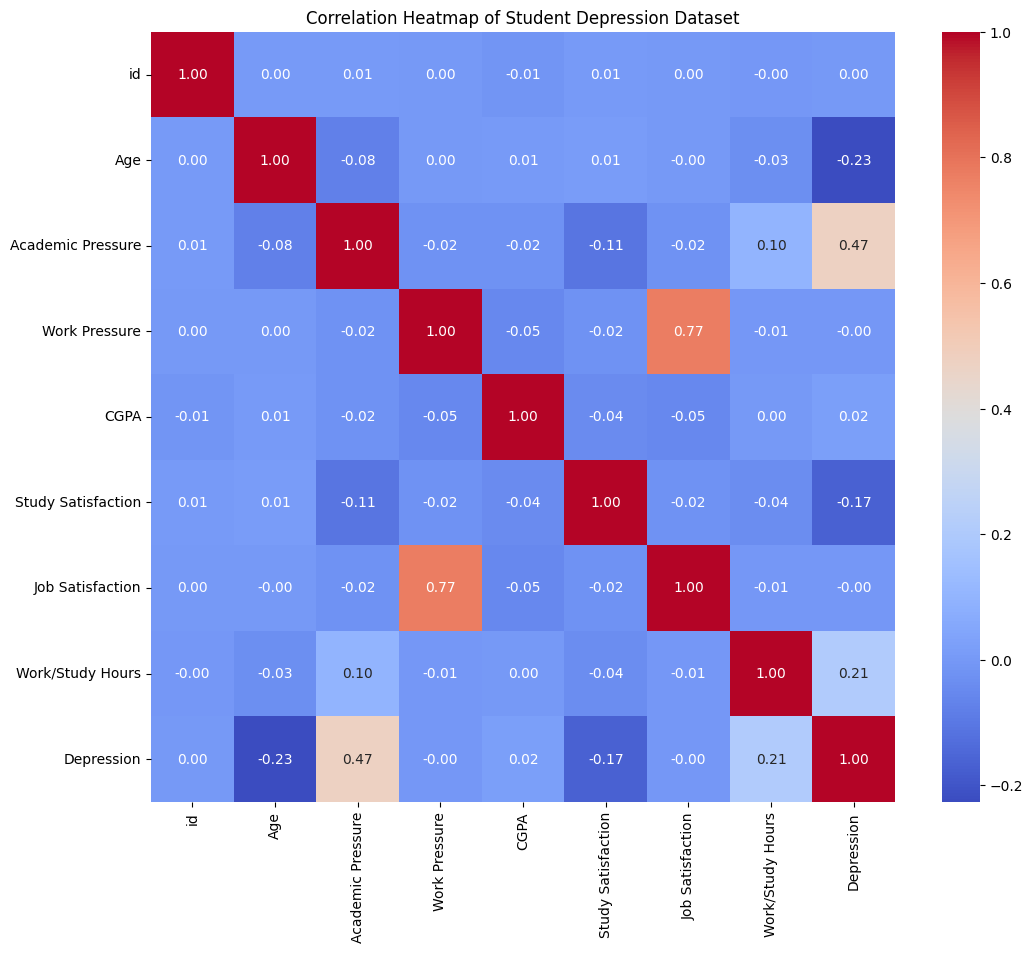

In [ ]:
!pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate correlation matrix with numeric_only=True
correlation_matrix = data.corr(numeric_only=True)

# Create the heatmap using seaborn
plt.figure(figsize=(12, 10))  # Adjust figure size if needed
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Student Depression Dataset')
plt.show()

In [ ]:
for i in data.select_dtypes(include=['object']).columns:
  print(f"{i}:{data[i].unique()}")


Gender:['Male' 'Female']
City:['Visakhapatnam' 'Bangalore' 'Srinagar' 'Varanasi' 'Jaipur' 'Pune' 'Thane'
 'Chennai' 'Nagpur' 'Nashik' 'Vadodara' 'Kalyan' 'Rajkot' 'Ahmedabad'
 'Kolkata' 'Mumbai' 'Lucknow' 'Indore' 'Surat' 'Ludhiana' 'Bhopal'
 'Meerut' 'Agra' 'Ghaziabad' 'Hyderabad' 'Vasai-Virar' 'Kanpur' 'Patna'
 'Faridabad' 'Delhi' 'Saanvi' 'M.Tech' 'Bhavna' "'Less Delhi'" 'City' '3'
 "'Less than 5 Kalyan'" 'Mira' 'Harsha' 'Vaanya' 'Gaurav' 'Harsh'
 'Reyansh' 'Kibara' 'Rashi' 'ME' 'M.Com' 'Nalyan' 'Mihir' 'Nalini'
 'Nandini' 'Khaziabad']
Profession:['Student' "'Civil Engineer'" 'Architect' "'UX/UI Designer'"
 "'Digital Marketer'" "'Content Writer'" "'Educational Consultant'"
 'Teacher' 'Manager' 'Chef' 'Doctor' 'Lawyer' 'Entrepreneur' 'Pharmacist']
Sleep Duration:["'5-6 hours'" "'Less than 5 hours'" "'7-8 hours'" "'More than 8 hours'"
 'Others']
Dietary Habits:['Healthy' 'Moderate' 'Unhealthy' 'Others']
Degree:['B.Pharm' 'BSc' 'BA' 'BCA' 'M.Tech' 'PhD' "'Class 12'" 'B.Ed' 'LLB' 'BE'
 

In [ ]:
# Removing single quotes from 'Profession' and 'Sleep Duration' columns
data['Profession'] = data['Profession'].str.replace("'", "")
data['Sleep Duration'] = data['Sleep Duration'].str.replace("'", "")

In [ ]:
# Replacing with NaN
data['Financial Stress'] = data['Financial Stress'].replace('?', np.nan)

In [ ]:
# Replace "3" with "Unknown"
data['City'] = data['City'].replace('3', 'Unknown')

In [ ]:
for i in data.select_dtypes(include=['object']).columns:
  print(f"{i}:{data[i].unique()}")

Gender:['Male' 'Female']
City:['Visakhapatnam' 'Bangalore' 'Srinagar' 'Varanasi' 'Jaipur' 'Pune' 'Thane'
 'Chennai' 'Nagpur' 'Nashik' 'Vadodara' 'Kalyan' 'Rajkot' 'Ahmedabad'
 'Kolkata' 'Mumbai' 'Lucknow' 'Indore' 'Surat' 'Ludhiana' 'Bhopal'
 'Meerut' 'Agra' 'Ghaziabad' 'Hyderabad' 'Vasai-Virar' 'Kanpur' 'Patna'
 'Faridabad' 'Delhi' 'Saanvi' 'M.Tech' 'Bhavna' "'Less Delhi'" 'City'
 'Unknown' "'Less than 5 Kalyan'" 'Mira' 'Harsha' 'Vaanya' 'Gaurav'
 'Harsh' 'Reyansh' 'Kibara' 'Rashi' 'ME' 'M.Com' 'Nalyan' 'Mihir' 'Nalini'
 'Nandini' 'Khaziabad']
Profession:['Student' 'Civil Engineer' 'Architect' 'UX/UI Designer'
 'Digital Marketer' 'Content Writer' 'Educational Consultant' 'Teacher'
 'Manager' 'Chef' 'Doctor' 'Lawyer' 'Entrepreneur' 'Pharmacist']
Sleep Duration:['5-6 hours' 'Less than 5 hours' '7-8 hours' 'More than 8 hours' 'Others']
Dietary Habits:['Healthy' 'Moderate' 'Unhealthy' 'Others']
Degree:['B.Pharm' 'BSc' 'BA' 'BCA' 'M.Tech' 'PhD' "'Class 12'" 'B.Ed' 'LLB' 'BE'
 'M.Ed' 'MSc' 

In [ ]:
data.describe()

,id,Age,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Work/Study Hours,Depression
count,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000,27901.000000
mean,70442.149421,25.822300,3.141214,0.000430,7.656104,2.943837,0.000681,7.156984,0.585499
std,40641.175216,4.905687,1.381465,0.043992,1.470707,1.361148,0.044394,3.707642,0.492645
min,2.000000,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,35039.000000,21.000000,2.000000,0.000000,6.290000,2.000000,0.000000,4.000000,0.000000
50%,70684.000000,25.000000,3.000000,0.000000,7.770000,3.000000,0.000000,8.000000,1.000000
75%,105818.000000,30.000000,4.000000,0.000000,8.920000,4.000000,0.000000,10.000000,1.000000
max,140699.000000,59.000000,5.000000,5.000000,10.000000,5.000000,4.000000,12.000000,1.000000


In [ ]:
# Converting binary categorical into numeric value 0 and 1
data['Have you ever had suicidal thoughts ?'] = data['Have you ever had suicidal thoughts ?'].map({'Yes':1, 'No':0})
data['Family History of Mental Illness'] = data['Family History of Mental Illness'].map({'Yes':1,'No':0})
data['Gender'] = data['Gender'].map({'Male':1,'Female':0})

In [ ]:
# Converting categorical variables into numeric values 0 and 1 using one hot encoding
data2=get_dummies(data, columns=['City', 'Profession','Sleep Duration','Dietary Habits','Financial Stress','Degree'])

In [ ]:
data2.shape

(27901, 120)

In [ ]:
# Seggreagating the data into X and Y features i.e., independent and dependent features
X=data2.drop('Depression',axis=1) # Independent features
Y=data2['Depression'] # Dependent features

In [ ]:
# Impute NaN values with the mean of each column before scaling and splitting
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')  # or strategy='median' etc.
X = imputer.fit_transform(X)

In [ ]:
# Normalization/ Standardisation of the dataset
X_scaled=StandardScaler().fit_transform(X)

In [ ]:
# Splitting the dataset into training and testing
X_train,X_test,Y_train,Y_test= train_test_split(X_scaled,Y, test_size=0.3,random_state=1)

In [ ]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Columns: 120 entries, id to Degree_PhD
dtypes: bool(108), float64(1), int64(11)
memory usage: 5.4 MB


In [ ]:
# Balancing the dataset using SMOTE technique
X_train, Y_train=SMOTE(random_state=1).fit_resample(X_train,Y_train) # Balancing the class labels

In [ ]:
Y_train.value_counts()

,count
Depression,
1,11408
0,11408


# Decision Trees

In [ ]:
from sklearn import tree

In [ ]:
dec_tree= tree.DecisionTreeClassifier(criterion='entropy',max_depth=5) # Decision Tree Classifier Building

In [ ]:
dec_tree.fit(X_train,Y_train) # Fitting decision tree classifier to the training set

DecisionTreeClassifier(criterion='entropy', max_depth=5)

In [ ]:
Y_pred=dec_tree.predict(X_test) # Predicted Y value on the test dataset

## Evaluating the performace of the model: Decision tree

In [ ]:
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred) # Calculating the accuracy of the model build
Recall= metrics.recall_score(Y_test,Y_pred) # Calculating the recall of the model build
Precision= metrics.precision_score(Y_test,Y_pred) # Calculating the precision of the model build
print('Accuracy:', Accuracy)
print('Recall:', Recall)
print('Precision:', Precision)

Accuracy: 0.8196153386692151
Recall: 0.8640422077922078
Precision: 0.8352295017653982


In [ ]:
conf_mat= metrics.confusion_matrix(Y_test,Y_pred) # Confusion matrix
conf_mat

array([[2603,  840],
       [ 670, 4258]])

## Validation of the Model build: decision tree

In [ ]:
from sklearn.model_selection import GridSearchCV

dec_tree2= tree.DecisionTreeClassifier(criterion='entropy',random_state=1) # Decision Tree Classifier Building

depth={'max_depth': [2,4,5,6,8,9,10,12,25,28,30,36]} # Grid of max_depth parameter length = 12

grid_search=GridSearchCV(estimator=dec_tree2,param_grid=depth,scoring='precision',cv=5)

grid_search.fit(X_train,Y_train) # Fitting decision tree classifier to the training set
best_depth= grid_search.best_params_ # Selecting the optimal parameter max_depth
print(best_depth)


{'max_depth': 2}


In [ ]:
 # Refitting the model with the optimal/best max_depth parameter selected based on the precision
dec_tree_best_depth= tree.DecisionTreeClassifier(criterion='entropy',max_depth=2) # Decision Tree Classifier Building
dec_tree_best_depth.fit(X_train,Y_train) # Fitting decision tree classifier to the training set
Y_pred=dec_tree_best_depth.predict(X_test) # Predicted Y value on the test dataset

In [ ]:
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred) # Calculating the accuracy of the model build
Recall= metrics.recall_score(Y_test,Y_pred) # Calculating the recall of the model build
Precision= metrics.precision_score(Y_test,Y_pred) # Calculating the precision of the model build
print('Accuracy:', Accuracy)
print('Recall:', Recall)
print('Precision:', Precision)

Accuracy: 0.7816270457531955
Recall: 0.7270698051948052
Precision: 0.8812100344318741


[[2960  483]
 [1345 3583]]


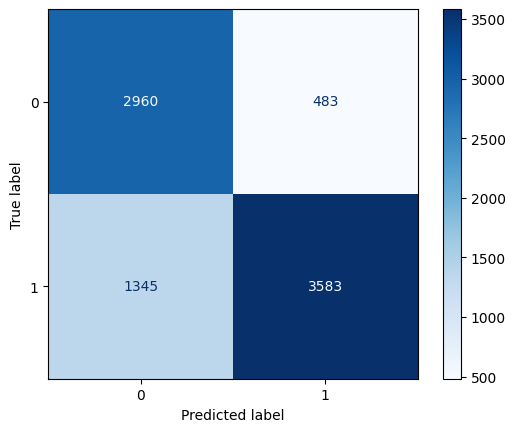

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate the confusion matrix
conf_matrix = confusion_matrix(Y_test, Y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='Blues')  # You can change the color map if needed
print(conf_matrix)

## Important features/variables


In [ ]:
# Selecting the optimal features
dec_tree_best_depth_impt_feat= tree.DecisionTreeClassifier(criterion='entropy',max_depth=2, random_state=1)
dec_tree_best_depth_impt_feat.fit(X_train,Y_train)
Y_pred_impt_feat=dec_tree_best_depth_impt_feat.predict(X_test)
imp_features = Series(dec_tree_best_depth_impt_feat.feature_importances_, index=data2.drop('Depression', axis=1).columns).sort_values(ascending=False)
#imp_features=Series(dec_tree_best_depth_impt_feat.feature_importances_,index=list(X)).sort_values(ascending=False)
print(imp_features)

Have you ever had suicidal thoughts ?    0.718417
Academic Pressure                        0.281583
Gender                                   0.000000
Age                                      0.000000
Work Pressure                            0.000000
                                           ...   
Degree_ME                                0.000000
Degree_MHM                               0.000000
Degree_MSc                               0.000000
Degree_Others                            0.000000
Degree_PhD                               0.000000
Length: 119, dtype: float64


In [ ]:
# Getting the important features in the dataset
X2=data2[['Have you ever had suicidal thoughts ?','Academic Pressure']]

# Normalization/ Standardisation of the new dataset with important features
X_scaled2=StandardScaler().fit_transform(X2)

# Dataset into training and testing
X_train,X_test,Y_train,Y_test= train_test_split(X_scaled2,Y, test_size=0.3,random_state=1)

# Balancing the dataset using SMOTE technique
X_train, Y_train=SMOTE(random_state=1).fit_resample(X_train,Y_train) # Balancing the class labels

In [ ]:
# Fitting decision tree on important features
from sklearn import tree
dec_tree_best_depth_impt_feat= tree.DecisionTreeClassifier(criterion='entropy',max_depth=2,random_state=1)
dec_tree_best_depth_impt_feat.fit(X_train,Y_train)
Y_pred_impt_feat=dec_tree_best_depth_impt_feat.predict(X_test)

# Selecting the max_depth parameter
depth={'max_depth': [2,6,10,12,25,28,30,36,38,40,52]}

grid_search=GridSearchCV(estimator=dec_tree_best_depth_impt_feat,param_grid=depth,scoring='precision',cv=10)

grid_search.fit(X_train,Y_train) # Fitting decision tree classifier to the training set
best_depth= grid_search.best_params_ # Selecting the optimal parameter max_depth
print(best_depth)

{'max_depth': 2}


In [ ]:
# Fitting decision tree with optimal max_depth parameter and important features
from sklearn import tree
dec_tree_best_depth_impt_feat= tree.DecisionTreeClassifier(criterion='entropy',max_depth=2)
dec_tree_best_depth_impt_feat.fit(X_train,Y_train)
Y_pred_impt_feat=dec_tree_best_depth_impt_feat.predict(X_test)

# Calculating the accuracy, recall and precision of the decision tree with optimal max_depth parameter and important features
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred_impt_feat) # Calculating the accuracy of the model build
Recall= metrics.recall_score(Y_test,Y_pred_impt_feat) # Calculating the recall of the model build
Precision= metrics.precision_score(Y_test,Y_pred_impt_feat) # Calculating the precision of the model build
print('Accuracy:', Accuracy)
print('Recall:', Recall)
print('Precision:', Precision)

# Calculating confusion matrix of the decision tree with optimal max_depth parameter and important features
conf_mat= metrics.confusion_matrix(Y_test,Y_pred_impt_feat) # Confusion matrix
print(conf_mat)

Accuracy: 0.7816270457531955
Recall: 0.7270698051948052
Precision: 0.8812100344318741
[[2960  483]
 [1345 3583]]


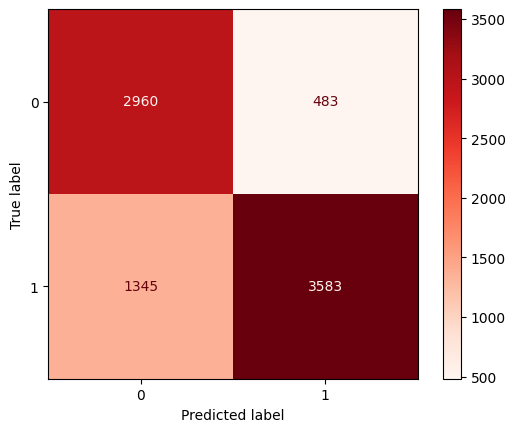

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Generate and display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat)
disp.plot(cmap='Reds', values_format='d')  # 'Blues' for color and 'd' for integer values

# Show the plot
plt.show()


# Random Forest

In [ ]:
from sklearn import ensemble
RF= ensemble.RandomForestClassifier(n_estimators=250,criterion='entropy',max_features='log2',random_state=1)
RF.fit(X_train,Y_train) # fitting random forest to training data
Y_pred=RF.predict(X_test)

In [ ]:
# Evaluating the random forest
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred) # Calculating the accuracy of the model build
Recall= metrics.recall_score(Y_test,Y_pred) # Calculating the recall of the model build
Precision= metrics.precision_score(Y_test,Y_pred) # Calculating the precision of the model build
print('Accuracy:', Accuracy)
print('Recall:', Recall)
print('Precision:', Precision)

Accuracy: 0.8095806952574364
Recall: 0.8668831168831169
Precision: 0.819961612284069


In [ ]:
conf_mat= metrics.confusion_matrix(Y_test,Y_pred) # Confusion matrix
print(conf_mat)

[[2505  938]
 [ 656 4272]]


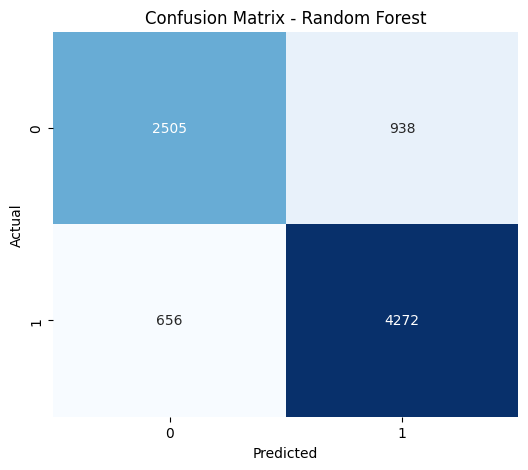

In [ ]:
# Plotting the heatmap
import seaborn as sns # Importing seaborn
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
sns.heatmap(conf_mat,annot=True, fmt='g' ,cmap='Blues' , cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV

# Selecting the optimal n_estimators parameter
RF1=ensemble.RandomForestClassifier(n_estimators=250,criterion='entropy',max_features=None,random_state=1)
ntrees={'n_estimators': [50,100,150,180,220,250,300,320,350]}

grid_search=GridSearchCV(estimator=RF1,param_grid=ntrees,scoring='precision',cv=10)

grid_search.fit(X_train,Y_train) # Fitting random forests classifier to the training set
best_nestimator= grid_search.best_params_ # Selecting the optimal parameter n_estimators
print(best_nestimator)

{'n_estimators': 50}


In [ ]:
# Refit the random forest on the optimal n_estimators parameter
RF2=ensemble.RandomForestClassifier(n_estimators=50,criterion='entropy',max_features=None,random_state=1)
RF2.fit(X_train,Y_train) # fitting random forest to training data
Y_pred=RF2.predict(X_test)

# Evaluating the refitted random forest with the optimal n_estimator parameter
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred) # Calculating the accuracy of the model build
Recall= metrics.recall_score(Y_test,Y_pred) # Calculating the recall of the model build
Precision= metrics.precision_score(Y_test,Y_pred) # Calculating the precision of the model build
print('Accuracy:', Accuracy)
print('Recall:', Recall)
print('Precision:', Precision)

Accuracy: 0.8095806952574364
Recall: 0.8668831168831169
Precision: 0.819961612284069


In [ ]:
conf_mat= metrics.confusion_matrix(Y_test,Y_pred) # Confusion matrix
print(conf_mat)

[[2505  938]
 [ 656 4272]]


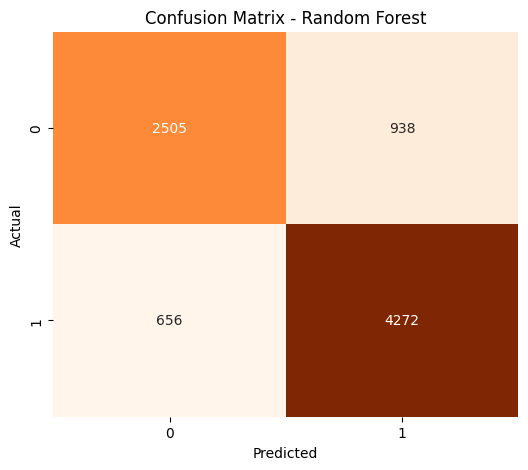

In [ ]:
# Plotting the heatmap
plt.figure(figsize=(6,5))
sns.heatmap(conf_mat,annot=True, fmt='g' ,cmap='Oranges' , cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

# Support Vector Machine

In [ ]:
from sklearn import svm
from sklearn.svm import SVC
svm_classifier= SVC(kernel='linear',random_state=1)
svm_classifier.fit(X_train,Y_train)

SVC(kernel='linear', random_state=1)

In [ ]:
Y_pred= svm_classifier.predict(X_test)

In [ ]:
# Evaluate the SVM classifier
from sklearn import metrics
Accuracy= metrics.accuracy_score(Y_test,Y_pred)
Precision=metrics.precision_score(Y_test, Y_pred)
Recall = metrics.recall_score(Y_test,Y_pred)
F1= metrics.f1_score(Y_test,Y_pred)

print('Accuracy:', Accuracy)
print('Precision:', Precision)
print('Recall:', Recall)
print('F1 score:', F1)

Accuracy: 0.7864054473778521
Precision: 0.7957799547852299
Recall: 0.8571428571428571
F1 score: 0.8253223915592028


In [ ]:
conf_mat=metrics.confusion_matrix(Y_test,Y_pred)
conf_mat

array([[2359, 1084],
       [ 704, 4224]])

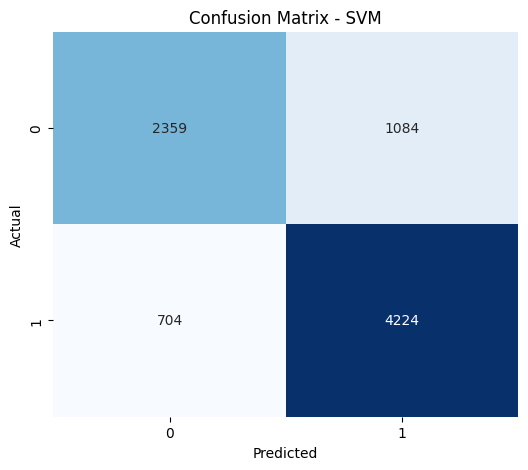

In [ ]:
# Plotting the heatmap
plt.figure(figsize=(6,5))
sns.heatmap(conf_mat,annot=True, fmt='g' ,cmap='Blues' , cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVM')
plt.show()

## Support Vector Machine with GridSearch

In [ ]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
model=Pipeline([('balancing',SMOTE(random_state=1)),('classification', SVC(random_state=1))])

ker_c={'classification__kernel':['linear','poly','rbf','sigmoid'],'classification__C':[0.001,0.01,0.1,1,10]}

grid_search1=GridSearchCV(estimator=model,param_grid=ker_c, scoring='recall',cv=5)


grid_search1.fit(X_train,Y_train)

best_params=grid_search1.best_params_
best_params
best_res= grid_search1.best_score_
#print(best_res)

In [ ]:
best_params

{'classification__C': 10, 'classification__kernel': 'rbf'}

In [ ]:
from sklearn import svm # Loading library of svm
from sklearn.svm import SVC # Loading function SVC from svm library
svm_classifier_rbf= SVC(kernel='rbf',C=10,random_state=1) # Building classifier
svm_classifier_rbf.fit(X_train,Y_train) # Building classifier on the train X and Y train values

SVC(C=10, random_state=1)

In [ ]:
# Predicting the test values using the classifier
Y_pred=svm_classifier_rbf.predict(X_test)

# Evaluating the model based on chosen kernel
from sklearn import metrics

Accuracy= metrics.accuracy_score(Y_test,Y_pred)
Precision=metrics.precision_score(Y_test, Y_pred)
Recall = metrics.recall_score(Y_test,Y_pred)
F1= metrics.f1_score(Y_test,Y_pred)

print('Accuracy:', Accuracy)
print('Precision:', Precision)
print('Recall:', Recall)
print('F1 score:', F1)

Accuracy: 0.8092223151355872
Precision: 0.8194897371954729
Recall: 0.8668831168831169
F1 score: 0.8425204614929495


In [ ]:
conf_mat=metrics.confusion_matrix(Y_test,Y_pred)
conf_mat

array([[2502,  941],
       [ 656, 4272]])

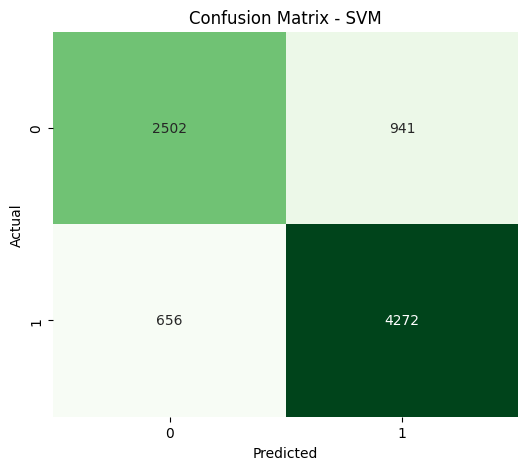

In [ ]:
# Plotting the heatmap
import matplotlib.pyplot as plt # Importing matplotlib.pyplot
import seaborn as sns # Importing seaborn

plt.figure(figsize=(6,5))
sns.heatmap(conf_mat,annot=True, fmt='g' ,cmap='Greens' , cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVM')
plt.show()

# Model Comparision

In [ ]:
from sklearn.metrics import accuracy_score, log_loss
# List of Classifiers

classifiers = [
    dec_tree_best_depth_impt_feat,
    RF2,
    svm_classifier_rbf
]


In [ ]:
#Accuracy and log loss of each classifier
log_cols=["Classifier", "Accuracy", "Log Loss"]
log = pd.DataFrame(columns=log_cols) # Changed 'Dataframe' to 'DataFrame'
for clf in classifiers:
  clf.fit( X_train, Y_train)
  name = clf.__class__.__name__
  print("="*30)
  print(name)
  print('***Results***')
#prediction
  train_predictions = clf.predict(X_test)
  acc = accuracy_score(Y_test,train_predictions)
  print("Accuracy: {:.4%}".format(acc))
# log loss require probabilities
  log_entry = pd.DataFrame([[name, acc*100, 11]], columns=log_cols)
  log = pd.concat([log, log_entry], ignore_index=True)
  print("="*30)
  print(log)

DecisionTreeClassifier
***Results***
Accuracy: 78.1627%
               Classifier   Accuracy Log Loss
0  DecisionTreeClassifier  78.162705       11


<ipython-input-106-784f70d4fd98>:22: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log = pd.concat([log, log_entry], ignore_index=True)


RandomForestClassifier
***Results***
Accuracy: 80.9581%
               Classifier   Accuracy Log Loss
0  DecisionTreeClassifier  78.162705       11
1  RandomForestClassifier  80.958070       11
SVC
***Results***
Accuracy: 80.9222%
               Classifier   Accuracy Log Loss
0  DecisionTreeClassifier  78.162705       11
1  RandomForestClassifier  80.958070       11
2                     SVC  80.922232       11


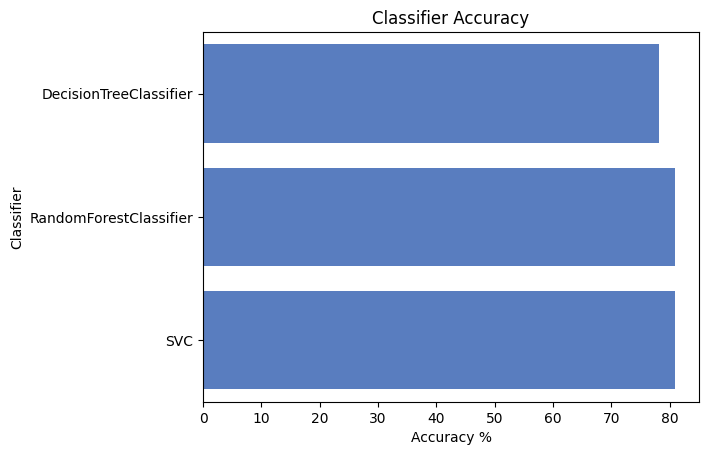

In [ ]:
# Plot a barchart to visualize the accuracy
sns.set_color_codes("muted")
sns.barplot(x='Accuracy', y='Classifier', data=log, color="b")

plt.xlabel('Accuracy %')
plt.title('Classifier Accuracy')
plt.show()